# Step 5 — missing rates in the target population (analysis only, nothing removed)

Missing rates of the features present in all 7 cycles 2005–2018 (`in_all_0518`), in the target population.

**Target population** (per cycle, `nhanes.cohort.population`): RIDAGEYR ≥ 20, not pregnant at exam (RIDEXPRG ≠ 1) and all nine PHQ-9 items DPQ010–DPQ090 answered 0–3. "Missing" = empty cell (SAS missing) after merging onto the population; refused / don't know codes (7/9, 77/99, …) are NOT counted here because the codes differ per variable. Renamed pairs (`rename_map.csv`) are merged first. Long-format modules (RXQ_RX) are skipped: they need aggregation before a per-person missing rate means anything.

**Output:**
- `missing_rates.csv`: one row per feature: module, variable, label, overall rate, rate per cycle, spread (max − min over cycles), likely cause, checkbox (code-all-that-apply item: only one substantive code ≥ 10, so an empty cell means "not chosen", not missing), empty_cycles (# cycles with ≥ 99% missing)
- `step5_counts.txt`: population size, distribution of missing rates, per-module summary

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes import io as nio  # noqa: E402
from nhanes.cohort import CYCLES, FAMILY, SHORT, population  # noqa: E402
from nhanes.paths import WORK  # noqa: E402

SUBSAMPLE = {"GLU": "fasting subsample", "TRIGLY": "fasting subsample", "OGTT": "fasting subsample",
             "PFAS": "1/3 subsample", "PFC": "1/3 subsample"}
SPECIAL = {7, 9, 77, 99, 777, 999, 7777, 9999, 77777, 99999}
BINS = [-0.001, 0.05, 0.2, 0.5, 0.8, 0.95, 1.0]
BIN_NAMES = ["<5%", "5-20%", "20-50%", "50-80%", "80-95%", ">=95%"]

## Missing rate of every feature, per cycle

In [2]:
cat = pd.read_csv(WORK / "feature_catalog.csv")
rmap = pd.read_csv(WORK / "rename_map.csv")
old_of = {(r.module, r.new): r.old for r in rmap.itertuples()}
feat = cat[cat.in_all_0518 & ~cat.long_format].copy()
feat["family"] = feat.module.replace(FAMILY)
feat = feat.drop_duplicates(["family", "variable"])
modules = sorted(set(feat.module) | {m for m, f in FAMILY.items() if f in set(feat.family)})

rates, sizes, women, values = {}, {}, {}, {}
for cycle in CYCLES:
    pop = population(cycle)
    sizes[SHORT[cycle]] = len(pop)
    women[SHORT[cycle]] = pop.RIAGENDR.eq(2)
    frames = {}
    for m in modules:
        d = nio.read_component(m, cycle, required=False)
        if d is not None:
            frames[FAMILY.get(m, m)] = pop[["SEQN"]].merge(d, on="SEQN", how="left")
    for r in feat.itertuples():
        d = frames.get(r.family)
        col = r.variable if d is not None and r.variable in d else old_of.get((r.module, r.variable))
        if d is None or col not in d:
            raise KeyError(f"{r.variable} not found in {r.family} {cycle}")
        rates[(r.module, r.variable, SHORT[cycle])] = (d[col].isna().mean(), d[col].isna())
        v = pd.to_numeric(d[col], errors="coerce").dropna().round(3).unique()
        values.setdefault((r.module, r.variable), set()).update(v[:50])

cyc = list(SHORT.values())
rows = []
for r in feat.itertuples():
    per = [rates[(r.module, r.variable, c)][0] for c in cyc]
    miss = pd.concat([rates[(r.module, r.variable, c)][1] for c in cyc], ignore_index=True)
    fem = pd.concat([women[c] for c in cyc], ignore_index=True)
    overall = miss.mean()
    if r.module in SUBSAMPLE:
        cause = SUBSAMPLE[r.module]
    elif overall > 0.4 and miss[~fem].mean() > 0.99 and miss[fem].mean() < 0.9:
        cause = "women only"
    elif overall > 0.05:
        cause = "skip pattern / not asked"
    else:
        cause = ""
    core = values.get((r.module, r.variable), set()) - SPECIAL
    rows.append({"module": r.module, "variable": r.variable, "label": r.label,
                 "missing_overall": round(overall, 4),
                 **{f"miss_{c}": round(p, 4) for c, p in zip(cyc, per)},
                 "spread": round(max(per) - min(per), 4), "likely_cause": cause,
                 "checkbox": len(core) == 1 and min(core) >= 10,
                 "empty_cycles": sum(p >= 0.99 for p in per)})
out = pd.DataFrame(rows).sort_values(["missing_overall", "module", "variable"])
out.to_csv(WORK / "missing_rates.csv", index=False)

## Summary

In [3]:
out["bin"] = pd.cut(out.missing_overall, BINS, labels=BIN_NAMES)
out["is_diet"] = out.module.isin(["DR1TOT", "DR2TOT"])
by_mod = (out.groupby("module")
          .agg(n=("variable", "size"), median=("missing_overall", "median"),
               lt20=("missing_overall", lambda s: int((s < 0.2).sum())),
               gt80=("missing_overall", lambda s: int((s > 0.8).sum())))
          .sort_values("median"))
spread = out[out.spread > 0.2].sort_values("spread", ascending=False)
part_empty = out[(out.empty_cycles > 0) & (out.empty_cycles < len(cyc))]
all_empty = out[out.empty_cycles == len(cyc)]
lines = ["population: age >= 20, not pregnant, PHQ-9 items all answered (0-3)",
         pd.Series(sizes, name="n").to_string(), f"total: {sum(sizes.values())}", "",
         f"features analysed: {len(out)} (all-7-cycle features; long-format RXQ_RX skipped)", "",
         "overall missing rate distribution (all / non-diet / diet DR1TOT+DR2TOT):",
         pd.DataFrame({"all": out.bin.value_counts(sort=False),
                       "non_diet": out[~out.is_diet].bin.value_counts(sort=False),
                       "diet": out[out.is_diet].bin.value_counts(sort=False)}).to_string(), "",
         "likely cause among features with missing >= 5%:",
         out[out.missing_overall >= 0.05].likely_cause.value_counts().to_string(), "",
         "per module (median missing rate, # features <20%, # features >80%):",
         by_mod.to_string(), "",
         f"features whose missing rate differs by >20 points across cycles: {len(spread)}",
         spread[["module", "variable", "label", *[f"miss_{c}" for c in cyc]]]
         .to_string(index=False, float_format=lambda x: f"{x:.2f}"), "",
         f"checkbox items (empty = not chosen): {int(out.checkbox.sum())}",
         out[out.checkbox].groupby("module").size().to_string(), "",
         f">= 99% missing in every cycle: {len(all_empty)}",
         all_empty.groupby("module").size().to_string(), "",
         f">= 99% missing in some cycles only: {len(part_empty)}",
         part_empty[["module", "variable", "label", "empty_cycles"]].to_string(index=False)]
(WORK / "step5_counts.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

population: age >= 20, not pregnant, PHQ-9 items all answered (0-3)
2005-06    3975
2007-08    5104
2009-10    5222
2011-12    4594
2013-14    4995
2015-16    4829
2017-18    4779
total: 33498

features analysed: 639 (all-7-cycle features; long-format RXQ_RX skipped)

overall missing rate distribution (all / non-diet / diet DR1TOT+DR2TOT):
        all  non_diet  diet
bin                        
<5%     187       110    77
5-20%   106        36    70
20-50%   55        23    32
50-80%   84        81     3
80-95%   77        66    11
>=95%   130       104    26

likely cause among features with missing >= 5%:
likely_cause
skip pattern / not asked    423
women only                   21
1/3 subsample                 5
fasting subsample             3

per module (median missing rate, # features <20%, # features >80%):
          n   median  lt20  gt80
module                          
DEMO     18  0.00000    14     1
SLQ       1  0.00000     1     0
HSQ       7  0.00000     6     1
HUQ       

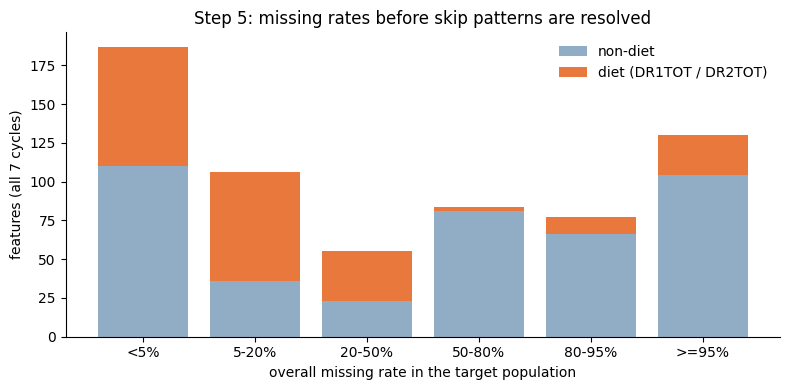

In [4]:
dist = pd.DataFrame({"non-diet": out[~out.is_diet].bin.value_counts(sort=False),
                     "diet (DR1TOT / DR2TOT)": out[out.is_diet].bin.value_counts(sort=False)})
fig, ax = plt.subplots(figsize=(8, 4))
bottom = np.zeros(len(dist))
for col, color in zip(dist.columns, ["#91ACC5", "#E9783D"]):
    ax.bar(dist.index.astype(str), dist[col], bottom=bottom, color=color, label=col)
    bottom += dist[col].to_numpy()
ax.set_xlabel("overall missing rate in the target population")
ax.set_ylabel("features (all 7 cycles)")
ax.set_title("Step 5: missing rates before skip patterns are resolved")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()